# Física Nuclear e de Partículas
## Exercicio de avaliación continua: análise de datos simulados. Desintegracións tauónicas.

# Solucións.
## 0. Preámbulo
O seguinte documento recolle o traballo realizado por Sebastián Táboas Pazo e Antón Torrado Puime, con respecto á asignatura de Física Nuclear e de Partículas. 
Neste informe traballamos cunha mostra de datos correspondentes a eventos de desintegracións de $\tau$ de 45 GeV de enerxía, de xeito similar a análise que sería necesario levar a cabo coa información arroxada polos sensores dun experimento real.


In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import namedtuple

In [78]:
datadir  = "."
datafile = "/taus_grupo_03.csv"
data     = pd.read_csv(datadir + datafile)

In [80]:
Particle = namedtuple('Particle', ('x', 'p', 'E', "name"))

def event_particles(data, event_number):
    dpars = data[data.event == event_number] ## get the particles of the same event
    npars = len(dpars) ## number of particles in the event
    pars  = [Particle(np.array((dpars.x.values[i] , dpars.y.values[i] , dpars.z.values[i])), 
                      np.array((dpars.px.values[i], dpars.py.values[i], dpars.pz.values[i])),
                      dpars.E.values[i], dpars.particleName.values[i]) for i in range(npars)]
    return pars

In [82]:
data

,event,particleName,x,y,z,px,py,pz,E
0,0,pi-,29.945739,-32.934099,-22.772744,6229.519182,-6832.184561,-4761.782868,10400.947602
1,1,pi+,-31.687219,-38.659060,1.182053,-3560.795070,-4341.870906,131.913468,5618.539443
2,2,pi-,39.466459,27.089810,14.440942,930.861462,638.647423,339.850064,1187.161098
3,2,pi-,38.699582,26.722155,16.978479,27731.619011,19141.053852,12166.997953,35825.660560
4,2,pi+,36.912647,29.598304,16.167772,5191.345948,4168.185398,2273.854686,7036.599833
...,...,...,...,...,...,...,...,...,...
36707,16033,e+,-32.872926,4.788124,37.369033,-21474.209427,3127.547556,24410.356688,32661.732014
36708,16034,pi-,-12.916729,-47.794332,6.989990,-9645.783164,-35752.263481,5228.745902,37398.191673
36709,16035,gamma,-16.720506,46.821471,5.307969,-4897.409506,13765.150646,1558.128963,14693.255529
36710,16035,gamma,-17.251376,46.626560,5.324841,-3092.029957,8376.131807,955.387365,8979.587871


As principais canles de desintegración do $\tau$ coñecidas pódense dividir en canles de desintegración hadrónica e en canles de desintegración leptónica. En orde de maior a menor probabilidade temos:

 * A: $\tau^\pm \longrightarrow \pi^\pm + \pi^0 + \nu_\tau (25.49\%)$
 * B: $\tau^\pm \longrightarrow e^\pm + \bar{\nu}_e + \nu_\tau (17.82\%)$
 * C: $\tau^\pm \longrightarrow \mu^\pm + \bar{\nu}_\mu + \nu_\tau (17.39\%)$
 * D: $\tau^\pm \longrightarrow \pi^\pm + \nu_\tau (10.82\%)$
 * E: $\tau^\pm \longrightarrow \pi^\pm + 2\pi^0 + \nu_\tau (9.26\%)$
 * F: $\tau^\pm \longrightarrow 2\pi^\pm + \pi^\mp + \nu_\tau (8.99\%)$
 * G: $\tau^\pm \longrightarrow 2\pi^\pm + \pi^\mp + \pi^0 + \nu_\tau (2.74\%)$
 * H: $\tau^\pm \longrightarrow \pi^\pm + 3\pi^0 + \nu_\tau (1.04\%)$

Onde as canles A, D, E, F, G e H se corresponden a canles de desintegración hadrónica, e B e C a canles de desintegración leptónica. No PDG recóllense un total de 46 canles de desintegración distintas.

Á súa vez, as canles principais de desintegración dos $\pi$ son:

* a: $\pi^+ \longrightarrow \mu^+ + \nu_\mu$
* b: $\pi^- \longrightarrow \mu^- + \bar\nu_\mu$
* c: $\pi^0 \longrightarrow 2\gamma$

Tamén compre sinalar que nun suceso de cascada electromagnética temos:

* $\gamma \longrightarrow e^{-} + e^{+}$

In [85]:
def translate(seq):    
    table = {
    ('gamma','gamma','pi+',):'A+', ('gamma','gamma','pi-',):'A-',
    ('e+',):'B+', ('e-',):'B-',
    ('mu+',):'C+', ('mu-',):'C-',
    ('pi+',):'D+', ('pi-',):'D-',
    ('gamma','gamma','gamma','gamma','pi+',):'E+', ('gamma','gamma','gamma','gamma','pi-',):'E-',
    ('pi+','pi+','pi-',):'F+', ('pi+','pi-','pi-',):'F-',
    ('e+','e-','gamma','pi+',):'G+', ('e+','e-','gamma','pi-',):'G-',
    ('e+','e-','gamma','gamma','gamma','pi+',):'H+', ('e+','e-','gamma','gamma','gamma','pi-',):'H-',
    ('e+','e+','e-','e-','gamma','gamma','pi+',):'I+', ('e+','e+','e-','e-','gamma','gamma','pi-',):'I-'
    } # Os Letra+ sinalan que proveñen dun tau+ e os Letra- dun tau-
    
    return table[tuple(seq)]   


def event_channel(data, event_number):
    edata = data[data.event == event_number] ## get the particles of the event
    pars  = list(edata.particleName) ## get the names of the particles 
    pars.sort() # non entendo por que o sort() deixome de ordenar correctamente cando o pasaba a strings
    spars = translate(pars)
    return spars

## 1. Cantos $\tau^-$ e $\tau^+$ hai na mostra?

In [88]:
%%time
# Contemos o número exacto de tau+ e tau-
n_events = max(data['event']) + 1 # total de eventos == taus totais

posibles = ('A+','B+','C+','D+','E+','F+','G+','H+','I+')
posiblesN = ('A-','B-','C-','D-','E-','F-','G-','H-','I-')

n_tau_plus = 0
for k in range(n_events):
    partic_ch = event_channel(data, k)
    for i in range(len(posibles)):
        if partic_ch == posibles[i]:
            n_tau_plus += 1

n_tau_minus = 0
for k in range(n_events):
    partic_ch = event_channel(data, k)
    for i in range(len(posibles)):
        if partic_ch == posiblesN[i]:
            n_tau_minus += 1

print(f'Dos {n_events} eventos, {n_tau_minus} son tauóns mentras que os outros {n_tau_plus} son antitauóns')
if n_events-n_tau_minus-n_tau_plus != 0:
    print('tes eventos sen clasificar')


Dos 16036 eventos, 10254 son tauóns mentras que os outros 5782 son antitauóns
CPU times: total: 9.83 s
Wall time: 9.85 s


## 2. Fraccións de desintegración.

- Cales son as canles detectadas e a súa fracción de producción?
- Asociade cada canal detectado con un canal de desintegración do $\tau$. Algúns canais detectados son moi pouco frecuentes: de onde veñen?
- Comparade as vosas fraccións coas do PDG. Cales son compatibles e cales non?

In [90]:
%%time
n_events = max(data['event']) + 1 # total de eventos

s_ch = np.zeros(10) # debería haber 8 canais, engadimos un último por se non é certo
rest_event = []

for k in range(n_events):
    partic_ch = event_channel(data, k)
    if partic_ch == 'A+' or partic_ch == 'A-': 
        s_ch[0] += 1
    elif partic_ch == 'B+' or partic_ch == 'B-':
        s_ch[1] += 1
    elif partic_ch == 'C+' or partic_ch == 'C-':
        s_ch[2] += 1
    elif partic_ch == 'D+' or partic_ch == 'D-':
        s_ch[3] += 1
    elif partic_ch == 'E+' or partic_ch == 'E-':
        s_ch[4] += 1
    elif partic_ch == 'F+' or partic_ch == 'F-':
        s_ch[5] += 1
    elif partic_ch == 'G+' or partic_ch == 'G-':
        s_ch[6] += 1
    elif partic_ch == 'H+' or partic_ch == 'H-':
        s_ch[7] += 1
    elif partic_ch == 'I+' or partic_ch == 'I-':
        s_ch[8] += 1
    else:
        rest_event.append(k)
        s_ch[9] += 1

if int(s_ch[9]) > 0:
    for i in range(len(rest_event)):
        print('faltan procesos por clasificar:', event_channel(data, rest_event[i]))
else:
    print('Todos os procesos están clasificados.')

canles = ('A','B','C','D','E','F','G','H','I')

for i in range(len(canles)):
    print(f'O número de desintegracións na canle {canles[i]} é {int(s_ch[i])}; asemade, a súa porcentaxe de desintegración é {100*int(s_ch[i])/n_events:.2f}%')
    # print(100*int(s_ch[i])/n_events**(3/2)) # non sei se así podo estimar unha incerteza para a porcentaxe
    # de desintegración, ao aplicar mínimos cadrados pois todas as incertezas son iguais, exactamente 100/n_event = 0,0062%

# O seguinte código queda en comentado xa que toma un tempo significativo de computación.

#nombres_eventos = []
#
# for i in range(0, 16035):
#     pars = event_particles(data, i)
#     nombres = sorted(p.name for p in pars)
#
#     if nombres not in nombres_eventos:
#         nombres_eventos.append(nombres)
#
# fraccion_desintegracion = []
#
# for canal in nombres_eventos:
#     contador = 0
#
#     for i in range(0, 16035):
#         pars = event_particles(data, i)
#         nombres = sorted(p.name for p in pars)
#
#         if nombres == canal:
#             contador += 1
#
#     fraccion_desintegracion.append(contador)
#
# print(nombres_eventos)
# print(fraccion_desintegracion)
# print('Número total de canales:', len(nombres_eventos))




Todos os procesos están clasificados.
O número de desintegracións na canle A é 3856; asemade, a súa porcentaxe de desintegración é 24.05%
O número de desintegracións na canle B é 2111; asemade, a súa porcentaxe de desintegración é 13.16%
O número de desintegracións na canle C é 2171; asemade, a súa porcentaxe de desintegración é 13.54%
O número de desintegracións na canle D é 3330; asemade, a súa porcentaxe de desintegración é 20.77%
O número de desintegracións na canle E é 1835; asemade, a súa porcentaxe de desintegración é 11.44%
O número de desintegracións na canle F é 2650; asemade, a súa porcentaxe de desintegración é 16.53%
O número de desintegracións na canle G é 46; asemade, a súa porcentaxe de desintegración é 0.29%
O número de desintegracións na canle H é 36; asemade, a súa porcentaxe de desintegración é 0.22%
O número de desintegracións na canle I é 1; asemade, a súa porcentaxe de desintegración é 0.01%
CPU times: total: 4.61 s
Wall time: 4.61 s


Na seguinte táboa recollemos as distintas canles observadas. Para conseguir identificalas, é necesario levar a cabo as seguintes consideracións:

Por un lado, os neutrinos e antineutrinos non interaccionan cos detectores, polo que non vai ser posible medilos experimentalmente e é necesario identificalos de xeito indirecto, recoñecendo a desintegración da cal proveñen. 

En segundo lugar, a presenza de fotóns é un indicio de desintegracións de $\pi^{0}$, o cal será necesario ter en conta á hora de relacionar as canles observadas experimentalmente coas teóricas. 

Por último, é posible recoñecer o fenómeno de cascada electromagnética nas canles $\pi^+ + e^+e^- + \gamma$, $\pi^- + e^+e^- + 3\gamma$, $\pi^- + e^+e^- + \gamma$, $\pi^+ + e^+e^- + 3\gamma$ e $\pi^- + 2e^+2e^- + 2\gamma$.


| Canle | Partículas detectadas | Desintegración orixinal | Eventos | Nota|
|:---:|:---|:---|---:|---:|
| D | $\pi^-$ | $\tau^- \rightarrow \pi^- + \nu_\tau$ | 2123 ||
| D | $\pi^+$ | $\tau^+ \rightarrow \pi^+ + \nu_\tau$ | 1207 ||
| F | $\pi^+ + \pi^- + \pi^-$ | $\tau^- \rightarrow 2\pi^- + \pi^+ + \nu_\tau$ | 1672 ||
| A | $\pi^- + 2\gamma$ | $\tau^- \rightarrow \pi^- +  \pi^0 + \nu_\tau$ | 2510 |Desintegración $\pi^{0}$|
| B | $e^-$ | $\tau^- \rightarrow e^- + \bar{\nu}_e + \nu_\tau$ | 1344 ||
| E | $\pi^- + 4\gamma$ | $\tau^- \rightarrow \pi^- + 2\pi^0 + \nu_\tau$ | 1186 |Desintegración $\pi^{0}$|
| F | $\pi^+ + \pi^+ + \pi^-$ | $\tau^+ \rightarrow 2\pi^+ + \pi^- + \bar{\nu}_\tau$ | 978 ||
| B | $e^+$ | $\tau^+ \rightarrow e^+ + \nu_e + \bar{\nu}_\tau$ | 767 ||
| E | $\pi^+ + 4\gamma$ | $\tau^+ \rightarrow \pi^+ + 2\pi^0 + \bar{\nu}_\tau$ | 649 |Desintegración $\pi^{0}$|
| A | $\pi^+ + 2\gamma$ | $\tau^+ \rightarrow \pi^+ + \pi^0 + \bar{\nu}_\tau$ | 1345 |Desintegración $\pi^{0}$|
| C | $\mu^+$ | $\tau^+ \rightarrow \mu^+ + \nu_\mu + \bar{\nu}_\tau$ | 803 ||
| C | $\mu^-$ | $\tau^- \rightarrow \mu^- + \bar{\nu}_\mu + \nu_\tau$ | 1368 ||
| A | $\pi^+ + e^+e^- + \gamma$ |$\tau^+ \rightarrow \pi^+ +  \pi^0 + \nu_\tau$| 20 |Cascada electromagnética|
|E  | $\pi^- + e^+e^- + 3\gamma$ | $\tau^- \rightarrow \pi^- + 2\pi^0 + \nu_\tau$ | 23 |Cascada electromagnética|
|A | $\pi^- + e^+e^- + \gamma$ |$\tau^- \rightarrow \pi^- +  \pi^0 + \nu_\tau$| 26 |Cascada electromagnética|
| E| $\pi^+ + e^+e^- + 3\gamma$ |$\tau^+ \rightarrow \pi^+ + 2\pi^0 + \bar{\nu}_\tau$ |  13 |Cascada electromagnética|
| E| $\pi^- + 2e^+2e^- + 2\gamma$ |$\tau^- \rightarrow \pi^- + 2\pi^0 + \nu_\tau$|  1 |Cascada electromagnética|

Á hora de considerar a incerteza dos nosos datos, partimos de que temos uns detectores ideais, polo que non haberá unha fonte de incerteza instrumental. Sen embargo é necesario considerar unha incerteza estadística, para a cal asumiremos que a nosa mostra segue unha distribución de Poisson, cuxa desviación ven dada por $\sqrt{N}$, e a incerteza da fracción de ramificación virá dada por propagación de incertezas.



| Canle | Fracción de ramificación experimental | Eventos | Fracción de ramificación do PDG |
|:---:|:---|:---|---:|
|A|0.243$\pm0.004$|3901$\pm62$|0.2549$\pm0.0009$|
|B|0.132$\pm0.003$|2111$\pm46$|0.1782$\pm0.0004$|
|C|0.135$\pm0.003$|2171$\pm47$|0.1739$\pm0.0004$|
|D|0.208$\pm0.004$|3330$\pm58$|0.1082$\pm0.0005$|
|E|0.117$\pm0.003$|1872$\pm43$|0.0926$\pm0.0010$|
|F|0.165$\pm0.003$|2650$\pm51$|0.0899$\pm0.0005$|
|G|0\%|0|0.0274$\pm0.0007$|
|H|0\%|0|0.0104$\pm0.0007$|


A fracción de ramificación referida aquí como A achégase en gran medida ós valores tabulados aportados polo PDG, cunha concordancia do 95.3\%. No referente ó resto das ramas, observamos unha concordancia do 74.07\% para a rama B, e do 77.63\% para a rama C, indicando que os nosos resultados se achegan ó esperado, a pesar de non concordar con exactitude; no resto de ramas a diferencia vólvese máis significativa.

Este feito non é de extrañar pois, por ser a rama máis probable, contamos cunha mostra significativamente maior para A. Segundo as ramas que estudamos teñen unha fracción de ramificación menor, a nosa mostra é máis reducida e polo tanto facer unha análise estadística vólvese menos preciso.

## 3. Comparade a distribución da enerxía do $e^\pm$ e do $\mu^\pm$ nos eventos cun só deses leptóns.

- Comparade agora esas distribucións coas do $\pi^\pm$ nos eventos onde só se emite un $\pi^\pm$. Explicade cualitativamente as diferencias.

CPU times: total: 8.08 s
Wall time: 8.1 s


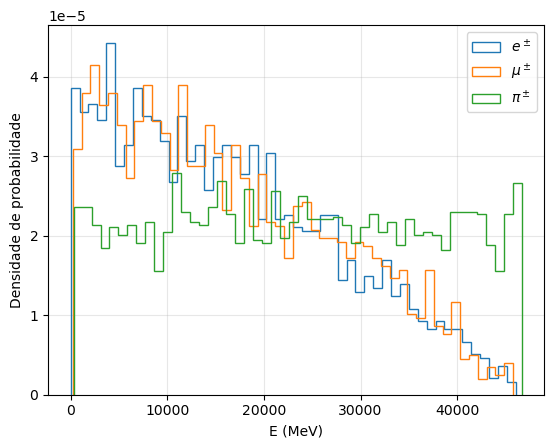

In [93]:
%%time
event_e = []
event_mu = []
event_pi = []
E_e = []; E_mu = []; E_pi = []

def E_espectro(data,event_number):
    dpars = data[data.event == event_number]
    pars = dpars.E.values
    return pars
    
for k in range(n_events):
    partic_ch = event_channel(data, k)
    if partic_ch == 'B+' or partic_ch == 'B-': # 1 electróns
        event_e.append(k)
        E_e.append(E_espectro(data,k)[0])
    elif partic_ch == 'C+' or partic_ch == 'C-': # 1 muóns
        event_mu.append(k)
        E_mu.append(E_espectro(data,k)[0])
    elif partic_ch == 'D+' or partic_ch == 'D-': # 1 pións
        event_pi.append(k)
        E_pi.append(E_espectro(data,k)[0])

plt.figure()
plt.hist(E_e, bins=50, histtype='step',
         density=True, label=r'$e^\pm$')

plt.hist(E_mu, bins=50, histtype='step',
         density=True, label=r'$\mu^\pm$')

plt.hist(E_pi, bins=50, histtype='step',
         density=True, label=r'$\pi^\pm$')

plt.xlabel('E (MeV)')
plt.ylabel('Densidade de probabilidade')
plt.legend()
plt.grid(alpha=0.3)


Na figura superior podemos observar unha clara semellanza entre as a distribución de enerxía dos $e^{\pm}$ e os $\mu^{\pm}$, ambos presentando unha pendente similar. A densidade de probabilidade achada é máxima para enerxías máis baixas, e decrece linealmente ao aumentar o rango de enerxías. Tanto $e^{\pm}$ coma $\mu^{\pm}$ son leptóns e presentan propiedades fundamentais similares, excepto pola masa. Por exemplo, ambas partículas fundamentais teñen mesma carga, espín, número leptónico e perciben as interaccións electromagnéticas e débil, pero non a forte. Na imaxe podemos observar como estas dúas partículas seguen o mesmo perfil de densidade de probabilidade dependente da enerxía.

Por outra banda, a densidade de probabilidade para o pión mantense aparentemente constante ó longo do espectro enerxético. O pión, a diferencia do $e^{\pm}$ e do $\mu^{\pm}$, é un hadrón, polo que é de esperar que as súa diferencia de propiedades con respecto ós leptóns anteriores se manifeste tamén neste aspecto.

## 4. Calculade a distancia de voo do $\tau$ reconstruíndo o seu vértice de desintegración e estimade a súa vida media.

-Verificade que a masa invariante dos eventos con dous $\gamma$ corresponde á masa dun $\pi^0$.

-Considerade que as partículas non están sometidas a un campo magnético e que as súas traxectorias son liñas rectas.

-Utilizade as canles con 1 $\pi^0$ ou con 3 pións cargados para obter a distribución da distancia de voo.

-É compatible a vosa vida media coa do PDG?

-Nestas canles, podedes reconstruír o momento do $\nu_\tau$ que escapa sen ser detectado?


Agora pretendemos calcular a masa invariante dos eventos con 2$\gamma$. Estes eventos son os que previamente denominamos como eventos A+ e A-. Dado que a masa invariante será a raiz do cadrado dos cadrimomentos, estamos interesados en resolver a seguinte expresión:

$$ s = \mathbb{P}_\tau^2 = m_{\tau^\pm}^2 = \left(\sum_{productos} \mathbb{P}_i\right)^2 = \left(\mathbb{P}_{\pi^\pm} + \mathbb{P}_{\pi^0}\right)^2 = \left( \mathbb{P}_{\pi^\pm} + \mathbb{P}_{\gamma_1} + \mathbb{P}_{\gamma_2}\right)^2 \Rightarrow \mathbb{P}_{\pi^0}^2 = m^2_{\pi^0} = \left(\mathbb{P}_{\gamma_1} + \mathbb{P}_{\gamma_2}\right)^2 = (E_{\gamma_1} + E_{\gamma_2})^2 - |\vec p_{\gamma_1} + \vec p_{\gamma_2}|^2 $$

In [136]:
%%time
# Isto podemos traducilo a m_pi0 = (E1 + E2)**2 - (px1 + px2)**2 - (py1 + py2)**2 - (pz1 + pz2)**2.
# Primeiro saquemos os datos que son os das canles A+ e A-, tal que

def E_mom(data,event_number):
    dpars = data[data.event == event_number]
    gammas = dpars[dpars.particleName == 'gamma']
    Enerxias = gammas.E.values
    enx = gammas.px.values
    eny = gammas.py.values
    enz = gammas.pz.values
    return Enerxias, enx, eny, enz

n = int(s_ch[0]) # lembremos que xa calculei a extensións das canles

E_1 = np.zeros(n)
E_2 = np.zeros(n)
px1, py1, pz1 = np.zeros(n), np.zeros(n), np.zeros(n)
px2, py2, pz2 = np.zeros(n), np.zeros(n), np.zeros(n)

i = 0
for k in range(n_events):
    partic_ch = event_channel(data, k)
    if partic_ch == 'A+' or partic_ch == 'A-':
        E_1[i], E_2[i] = E_mom(data,k)[0]
        px1[i], px2[i] = E_mom(data,k)[1]
        py1[i], py2[i] = E_mom(data,k)[2]
        pz1[i], pz2[i] = E_mom(data,k)[3]
        i += 1

m_pi0 = np.zeros(n)
for k in range(n):
    m_pi0[k] = (E_1[k] + E_2[k])**2 - (px1[k] + px2[k])**2 - (py1[k] + py2[k])**2 - (pz1[k] + pz2[k])**2
m_pi0_media = np.sqrt(sum(m_pi0)/n)

print(f'Masa calculada en MeV: {m_pi0_media:.4f}')

Masa calculada en MeV: 134.9766
CPU times: total: 31 s
Wall time: 31.3 s


Para calcular a masa invariante do $\pi^0$, seleccionamos os eventos que conteñen dous fotóns e extraemos as súas enerxías e compoñentes do momento lineal. A continuación, sumamos os cuadrimomentos dos dous fotóns e calculamos o seu cadrado, empregando a expresión da masa invariante descrita previamente. Finalmente, extraemos a raíz cadrada e calculamos a media das masas invariantes de todos os eventos. 

Levando a cabo este procedemento, obtemos como resultado que a masa experimental do $\pi^0$ é 134.9766MeV, onde cabe destacar que a incerteza asociada ó noso cálculo é nula, é dicir, cada valor individual de masa invariante é idéntico, o que ven necesariamente dado polo feito de que os datos empregados foron xerados por simulación. Podemos comprobar este resultado coa masa tabulada presente no PDG para comprobar a correcta identificación da partícula, que é de 134.9766MeV. Como vemos, os nosos resultados concordan cos valores teóricos esperables, o que nos serve tamén para asegurar que os fotóns observados proveñen de desintegracións $\pi^0$.

In [138]:
# Parte 4. Imos calcular a distancia de voo (L) dos tauons que é basicamente a distancia dende a orixe até onde se detectan partículas novas,
# i.e., coller o módulo das distancias que percorreron os productos de desintegración, logo promediala e xa temos unha distancia de voo media (<L>).
# Con isto preténdese medir o tempo de vida media que será <L> = v * <t>, pero non coñecemos a v dos tauons, pero si a enerxía que é de 45 GeV
# xogando un pouco coa relatividade especial: v = beta * c = c * np.sqrt(1 - 1/gamma**2) onde gamma = (E/m)_tauon pero tamén o tempo propio tense
# que tranformar segundo <t> = gamma * tau e así tau = <L>/(c*gamma*beta) que é o tempo de vida media

E_tau = 45 * 1000 # en MeV
m_tau = 1777 # MeV
c_luz = 3*10**8 # m/s
c_luz = c_luz * 1000 # en mm/s
gamma = E_tau/m_tau; beta = np.sqrt(1 - 1/gamma**2)

# nos nosos datos temos valores x,y,z que representan o punto do detector onde se mediron, temos tamén os momentos das partículas, se temos que
# P_tau = \Sum P_productos onde P_i é o cadrimomento o que temos é (45, p) = (sum(E_i), sum(p_i)) ==> p_tau = sum(p_i); fáltanos o momento dos 
# neutrinos que non se poden medir, podemos coller E_nu = |p_nu| porque m_nu = 0 e logo 45 - sum(E_i) = sum(E_nu) = sum(|p_nu|)

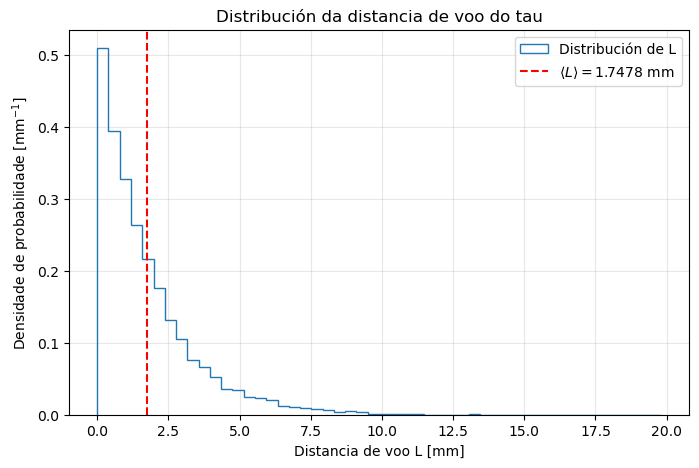

Número de eventos válidos: 8341
Distancia media: (1.74778 ± 0.01902) mm
Desviación estándar: 1.73719 mm
Vida media: (2.30240e-13 ± 2.50571e-15) s
CPU times: total: 24.4 s
Wall time: 24.4 s


In [139]:
%%time
def reconstruct_vertex(evt):

    A = np.zeros((3,3))
    b = np.zeros(3)

    for _, row in evt.iterrows():
        r = np.array([row.x, row.y, row.z])
        p = np.array([row.px, row.py, row.pz])
        u = p / np.linalg.norm(p)

        Ai = np.eye(3) - np.outer(u, u)
        A += Ai
        b += Ai @ r

    v = np.linalg.solve(A, b)
    return v


# Selección de eventos y reconstrucción de vértices
L = []

for k in range(n_events):
    partic_ch = event_channel(data, k)

    if partic_ch in ['A+', 'A-', 'E+', 'E-', 'F+', 'F-']:

        evt = data[data.event == k]

        try:
            v = reconstruct_vertex(evt)
            L.append(np.linalg.norm(v))

        except np.linalg.LinAlgError:
            continue


# Cálculo de la distancia media y su incertidumbre
N = len(L)

L_medi = np.mean(L)
sigma_L = np.std(L, ddof=1)
inc_L = sigma_L / np.sqrt(N)


# Cálculo de la vida media y su incertidumbre
tau_m = L_medi / (c_luz * beta * gamma)
inc_tau = inc_L / (c_luz * beta * gamma)


# Representación gráfica
plt.figure(figsize=(8,5))

plt.hist(L, bins=50, histtype='step', density=True,
         label='Distribución de L')

plt.axvline(L_medi, color='red', linestyle='--',
            label=fr'$\langle L\rangle = {L_medi:.4f}$ mm')

plt.xlabel('Distancia de voo L [mm]')
plt.ylabel('Densidade de probabilidade [mm$^{-1}$]')
plt.title('Distribución da distancia de voo do tau')
plt.legend()
plt.grid(alpha=0.3)

plt.show()


# Resultados
print(f'Número de eventos válidos: {N}')
print(f'Distancia media: ({L_medi:.5f} ± {inc_L:.5f}) mm')
print(f'Desviación estándar: {sigma_L:.5f} mm')
print(f'Vida media: ({tau_m:.5e} ± {inc_tau:.5e}) s')

O obxectivo deste programa é reconstruír o vértice de desintegración do $\tau$ e calcular a distancia que percorre desde o punto de produción ata o punto de desintegración. Para iso, utilizamos as posicións e os momentos das partículas de cada evento, aproximando as súas traxectorias mediante liñas rectas. A partir destas traxectorias, buscamos o punto que minimiza a suma das distancias cadráticas ás rectas, obtendo así o vértice reconstruído.
Finalmente, calculamos a distancia entre o vértice de produción e o de desintegración para cada evento, construímos a súa distribución e obtemos a distancia media de voo. Empregando a relación relativista $\langle L\rangle=\beta\gamma c\tau$, estimamos a vida media propia do $\tau$ e comparamos o resultado co valor tabulado no PDG.

Para considerar a incerteza do noso resultados, de novo será necesario ter en conta a incerteza estadística. Para a distancia de voo teremos:
\begin{equation}
\Delta L=\frac{\sigma_{L}}{\sqrt{N}}
\end{equation}

onde $\sigma_{L}$ é a desviación estándar; por propagación de incertezas podemos achar $\Delta \tau$.

Tras empregar este código, os resultados obtidos son os seguintes: 

 - A distancia de voo dos nosos resultados é $(1.75\pm0.02)$ mm.
  - A vida media do $\tau$ calculada é de $(2.30 \pm 0.03)\times 10^{-13}$s.


Podemos comparar a vida media calculada coa información presente no PDG, que indica que a vida media do tauón é de $(290\pm0.5)\cdot 10^{-15}$ s. Como vemos, os nosos resultados son lixeiramente inferiores ós tabulados, cunha concordancia do 79.31\%. Esta diferencia non pode ser xustificada únicamente pola consideración da incerteza calculada; sen embargo, ambos resultados coinciden na orde de magnitude e son significativamente próximos.
    


In [140]:
# Cálculo con axuste lineal da lei de desintegración

from scipy.optimize import curve_fit

def exp(L, A, ell): # ell == L media
    return A*np.exp(-L/ell)

counts, bins = np.histogram(L, bins=50)
centers = 0.5*(bins[1:] + bins[:-1])

popt, pcov = curve_fit(exp, centers, counts, p0 = [counts.max(), L_medi])
A_axustado, ell_axustado = popt
sA, sell = np.sqrt(np.diag(pcov))

tau_m = ell_axustado/(c_luz*beta*gamma)
stau = sell/(c_luz*beta*gamma)
print(f'o tempo de vida media é <tau> = {tau_m*10**15:.4} +- {stau*10**15:.2} fs')

o tempo de vida media é <tau> = 233.9 +- 1.9 fs


Unha mellor estimación pode ser lograda aplicando un axuste sobre a lei de desintegración, tal e como facemos no código superior. 

Ao levalo a cabo, os nosos resultados son dunha vida media de $(2.34 \pm 0.02)\cdot 10^{-13}$ s, pasando a ter unha concordancia cos valores do PDG do 80.65\%, lixeiramente mellor.

Por último hai que medir o momento dos neutrinos invisibles. Para iso, por conservación do cuadrimomento:

$$\mathbb{P}_{\tau} = \sum \mathbb{P}_{\text{visibles}} + \sum \mathbb{P}_{\nu_i}$$

simplificamos o problema a só aquelas canles (A, E, F) onde se escapa un único neutrino que é o tauónico, logo

$$\mathbb{P}_{\tau} = \sum \mathbb{P}_{\text{visibles}} + \mathbb{P}_{\nu_\tau} \Rightarrow (E_\tau, \vec p_\tau) = (E_{\text{visibles}} + E_{\nu_\tau},\  \vec p_{\text{visibles}} + \vec p_{\nu_\tau})$$
Logo
$$E_\nu = E_\tau - E_{\text{visibles}};\ \ \ \vec p_\nu = \vec p_\tau - \vec p_{\text{visibles}}$$
que ademais como $m_{\nu} \approx 0$ temos que $E_\nu = |\vec p_\nu|$

In [151]:
%%time
# definimos antes E_tau e m_tau. As canles que só teñen un neutrino son a A, E e F
# por invarianza da norma do cadrimomento m_tau^2 = E_tau^2 - p_tau^2 ==> |p_tau| = sqrt(E_tau^2 - m_tau^2)
modulo_tau = np.sqrt(E_tau**2 - m_tau**2)

resultados = []
errores = 0

for k in range(n_events):

    partic_ch = event_channel(data, k)

    if partic_ch in ['A+', 'A-', 'E+', 'E-', 'F+', 'F-']:

        event_nu = data[data.event == k]

        # Reconstrucción de la dirección y del momento del tauón
        V = reconstruct_vertex(event_nu)
        u_tau = V / np.linalg.norm(V)
        p_tau = modulo_tau * u_tau

        # Momento total de las partículas visibles
        px_visible = event_nu.px.sum()
        py_visible = event_nu.py.sum()
        pz_visible = event_nu.pz.sum()

        # Momento del neutrino por conservación del momento
        pxnu = p_tau[0] - px_visible
        pynu = p_tau[1] - py_visible
        pznu = p_tau[2] - pz_visible

        modulo_pnu = np.sqrt(pxnu**2 + pynu**2 + pznu**2)

        # Energía del neutrino por conservación de la energía
        E_visible = event_nu.E.sum()
        E_nu = E_tau - E_visible

        # Diferencia E - |p| (el neutrino es prácticamente sin masa)
        diferencia = E_nu - modulo_pnu

        resultados.append({
            'Evento': k,
            'Canal': partic_ch,
            'E_nu [MeV]': E_nu,
            'px_nu [MeV]': pxnu,
            'py_nu [MeV]': pynu,
            'pz_nu [MeV]': pznu,
            '|p_nu| [MeV]': modulo_pnu,
            'E_nu - |p_nu| [MeV]': diferencia
        })

        if E_nu < 0:
            errores += 1

# Convertimos los resultados en una tabla
df_neutrinos = pd.DataFrame(resultados)

print("RECONSTRUCCIÓN DEL CUADRIMOMENTO DE LOS NEUTRINOS")
print("=" * 65)
print(df_neutrinos.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

print("\nRESUMO")
print("=" * 65)
print(f"Eventos analizados: {len(resultados)}")
print(f"Eventos con enerxía negativa: {errores}")
print(f"Porcentaxe de eventos con enerxía negativa: {100*errores/len(resultados):.2f}%")

RECONSTRUCCIÓN DEL CUADRIMOMENTO DE LOS NEUTRINOS
 Evento Canal  E_nu [MeV]  px_nu [MeV]  py_nu [MeV]  pz_nu [MeV]  |p_nu| [MeV]  E_nu - |p_nu| [MeV]
      2    F-     950.579      615.414      678.256      294.669       962.079              -11.500
      5    A-   26444.317   -19364.521      417.613   -18002.137     26443.071                1.247
      6    A-   12958.786    -7010.661     3167.985   -10428.953     12959.496               -0.710
      8    F-    2861.957     1224.223     -989.579    -2402.684      2872.434              -10.478
      9    E-   10041.108     3790.440     5823.501    -7249.477     10041.689               -0.581
     11    F-   32001.291     6980.841    24095.896    19866.302     32000.223                1.068
     12    F+    -584.264     -576.103     -172.857      118.326       613.005            -1197.270
     14    F-    9108.150    -5442.681     2944.791     6681.435      9106.929                1.221
     15    E+   20125.140    15167.856     1193.99

Algúns valores da táboa que obtivemos non poden ser correctos, xa que presentan unha enerxía reconstruída para o neutrino negativa ou non cumpren a condición de que a súa enerxía debe ser aproximadamente igual ao módulo do seu momento ($E_\nu \simeq |\vec p_\nu|$). A continuación, centrarémonos únicamente naqueles casos nos que se cumplan os seguintes dous criterios:
* -A enerxía reconstruída debe ser positiva.
* -A diferencia entre enerxía e momento debe ser menor a 1 MeV

In [167]:
modulo_tau = np.sqrt(E_tau**2 - m_tau**2)

resultados = []
errores = 0

for k in range(n_events):

    partic_ch = event_channel(data, k)

    if partic_ch in ['A+', 'A-', 'E+', 'E-', 'F+', 'F-']:

        event_nu = data[data.event == k]

        # Reconstrucción de la dirección y del momento del tauón
        V = reconstruct_vertex(event_nu)
        u_tau = V / np.linalg.norm(V)
        p_tau = modulo_tau * u_tau

        # Momento total de las partículas visibles
        px_visible = event_nu.px.sum()
        py_visible = event_nu.py.sum()
        pz_visible = event_nu.pz.sum()

        # Momento del neutrino
        pxnu = p_tau[0] - px_visible
        pynu = p_tau[1] - py_visible
        pznu = p_tau[2] - pz_visible

        modulo_pnu = np.sqrt(pxnu**2 + pynu**2 + pznu**2)

        # Energía del neutrino
        E_visible = event_nu.E.sum()
        E_nu = E_tau - E_visible

        # Diferencia entre energía y módulo del momento
        diferencia = E_nu - modulo_pnu

        resultados.append({
            'Evento': k,
            'Canal': partic_ch,
            'E_nu [MeV]': E_nu,
            'px_nu [MeV]': pxnu,
            'py_nu [MeV]': pynu,
            'pz_nu [MeV]': pznu,
            '|p_nu| [MeV]': modulo_pnu,
            'E_nu - |p_nu| [MeV]': diferencia
        })

        if E_nu < 0:
            errores += 1

# Crear tabla con todos los eventos
df_neutrinos = pd.DataFrame(resultados)

# Filtrar los eventos que cumplen ambos criterios
df_neutrinos_validos = df_neutrinos[
    (df_neutrinos['E_nu [MeV]'] > 0) &
    (np.abs(df_neutrinos['E_nu - |p_nu| [MeV]']) < 1)
].copy()

# Mostrar únicamente los eventos seleccionados
print("EVENTOS QUE CUMPLEN OS CRITERIOS")
print("=" * 65)
print(df_neutrinos_validos.to_string(
    index=False,
    float_format=lambda x: f'{x:.3f}'
))

# Resumen
print("\nRESUMEN")
print("=" * 65)
print(f"Eventos analizados: {len(df_neutrinos)}")
print(f"Eventos con energía negativa: {errores}")
print(f"Eventos descartados: {len(df_neutrinos) - len(df_neutrinos_validos)}")
print(f"Eventos seleccionados: {len(df_neutrinos_validos)}")
print(f"Porcentaje seleccionado: "
      f"{100 * len(df_neutrinos_validos) / len(df_neutrinos):.2f}%")

EVENTOS QUE CUMPLEN LOS CRITERIOS
 Evento Canal  E_nu [MeV]  px_nu [MeV]  py_nu [MeV]  pz_nu [MeV]  |p_nu| [MeV]  E_nu - |p_nu| [MeV]
      6    A-   12958.786    -7010.661     3167.985   -10428.953     12959.496               -0.710
      9    E-   10041.108     3790.440     5823.501    -7249.477     10041.689               -0.581
     20    A+   32420.192     9266.933    -6361.123   -30408.346     32419.244                0.947
     24    A+   26970.918    15915.416    21656.809     2250.756     26970.052                0.866
     25    A-    6358.158     4208.740     4580.482     1318.779      6358.733               -0.576
     30    F-    9627.447     6679.595    -6767.930    -1505.265      9627.445                0.002
     31    A-    3633.257     2976.589      588.745    -1998.598      3633.332               -0.075
     33    E-    7739.809    -4316.453     5762.456     2837.898      7738.949                0.860
     43    E-    6948.658     6305.113     1695.189     2378.886  

A táboa superior recolle os nosos cálculos do momento dos neutrinos que si son consistentes coas consideracións de masa cuasi nula e enerxía negativa. Como podemos ver, o número total de eventos seleccionados reduciuse significativamente, pasando a contar únicamente con 3415 eventos. Dado que estamos asumindo que partimos, en todos os casos, de 45 GeV de enerxía, a fonte de erro que estamos a considerar é a reconstrucción da dirección, que calculamos previamente. Os resultados recollidos nesta última táboa asemellan consistentes coas previsións esperables.

## 5. Universalidade leptónica

No voso universo, o $\tau$ acóplase ao $W$ exactamente do mesmo xeito que o $\mu$ e o $e$. A partir da vosa fracción de desintegración $B(\tau^- \to e^- \bar{\nu}_e \nu_\tau)$, da vida media do muón e das masas do $\mu$ e do $\tau$, predecide a vida media do $\tau$ e comparádea coa que medístedes no apartado 4.

O primeiro é cargar a fracción da canle que calculamos no punto 2, as canles monoelectrónicas son as B+ e B- e as muónicos C+ e C-, e as masas e tempos de vida media do $e^+$ e do $\mu^+$.

In [171]:
# os nosos valores para t_tau foron tau_m \pm stau
m_e = 0.511 # MeV
m_mu = 105.66 # MeV
t_e = 4.6 * 3600 * 24 * 365 * 10**26 # "El límite inferior experimental de la vida media de un electrón es de 4,6 × 10^26 años" segundo a wikipedia
t_mu = 2.2 * 10**(-6)
Br_e = float(s_ch[1])/n_events
Br_mu = float(s_ch[2])/n_events

Dos apuntamentos considerando que os tres leptóns acóplanse exactamente igual ao bosón ($g^\tau_W = g^\mu_W = g^e_W = g_W$) e $\mathcal{Br}(\mu\to e + \bar\nu_e +\nu_\mu)$ = 1
$$\Gamma (\mu\to e + \bar\nu_e +\nu_\mu) = \frac{1}{\tau_\mu} = \frac{G_F^2m_\mu^5}{192\pi^3} \Rightarrow \frac{G_F^2}{192\pi^3} = \frac{1}{m_\mu^5\tau_\mu} $$
$$\Gamma (\tau\to e + \bar\nu_e +\nu_\tau) = \frac{\mathcal{Br}(\tau\to e + \bar\nu_e +\nu_\tau)}{\tau_\tau} = \frac{G_F^2m_\tau^5}{192\pi^3} \Rightarrow \frac{G_F^2}{192\pi^3} = \frac{\mathcal{Br}(\tau\to e + \bar\nu_e +\nu_\tau)}{m_\tau^5\tau_\tau}$$
$$\Rightarrow \frac{1}{m_\mu^5\tau_\mu} = \frac{\mathcal{Br}(\tau\to e + \bar\nu_e +\nu_\tau)}{m_\tau^5\tau_\tau} \Rightarrow \tau_\tau = \tau_\mu \left(\frac{m_\mu}{m_\tau}\right)^5 \mathcal{Br}(\tau\to e + \bar\nu_e +\nu_\tau) $$

In [189]:
# Fracción de desintegración electrónica do tau
Br_e = float(s_ch[1]) / n_events

# Incerteza estadística da fracción (binomial)
dBr_e = np.sqrt(Br_e * (1 - Br_e) / n_events)

t_tau = t_mu * (m_mu/m_tau)**5 * Br_e
dt_tau = t_tau * dBr_e / Br_e

print(f'A vida media estimada: ({t_tau*1e15:.3f} ± {dt_tau*1e15:.3f}) fs')


A vida media estimada: (215.244 ± 4.366) fs


No código superior calculamos a incerteza da fracción de desintegración dun xeito análogo a como fixemos con anterioridade, dada pola incerteza estadística asociada ó número finito de sucesos. As masas do muón e do tauón as consideramos coñecidas cunha precisión suficiente como para despreciar a súa incerteza.
A vida media que estimamos polo acoplo para o tauón da como resultado $(2.15\pm0.04)\cdot 10^{-13}$ s, fronte ós $(2.30 \pm 0.03)\times 10^{-13}$s estimados coa distancia de voo dos tauóns, e os $(2.9\pm0.5)\cdot 10^{-13}$ s tabulados na páxina do PDG.

Como podemos observar, o cálculo da vida media realizado mediante a estimación da distancia de voo arroxa uns valores lixeiramente máis próximos ós do PDG.